# Lab 5: 4-ASK and Envelope Detection

Every modulation scheme you build encodes information in some property of a transmitted
waveform: phase, amplitude, or some combination of the two. This lab isolates amplitude on
its own. You will send a 4-level amplitude-shift-keyed (4-ASK) signal from one
software-defined radio to another, and recover it using only the *magnitude* of what
arrives, never its phase.

That choice has a consequence worth noticing before you start. Two independent radios, each
running its own free-running local oscillator, will never agree perfectly on carrier phase or
frequency. A receiver that depends on phase has to actively track and correct for that
mismatch. A receiver that only looks at magnitude does not have to: the rotation is still
present in the raw samples, but it never touches the number you actually base a decision on.
You will see this directly, side by side, later in the lab: a raw IQ scatter that spirals, and
an amplitude histogram built from those same samples that does not.

Before any of that, though, every SDR receiver carries its own quiet, constant bias: a DC
offset baked into the hardware, present regardless of whatever is or isn't on the air.
Estimating and removing that offset is where this lab starts. 

*A suggestion is to use wired transmission for this experiment*

## Hardware Setup

Configure both radios: sample rate, carrier frequency, transmit scaling, and a fixed manual
receive gain. These values stay fixed for the rest of the lab, with one exception — the
transmit gain, which you will sweep deliberately in the final task.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import adi
import time

fs = int(0.6e6)
fc = int(763e6)
tx_scale = 2**14

tx_sdr = adi.Pluto("ip:192.168.2.1")
rx_sdr = adi.Pluto("ip:192.168.3.1")

tx_sdr.sample_rate = fs
tx_sdr.tx_lo = fc
tx_sdr.tx_rf_bandwidth = fs
tx_sdr.tx_hardwaregain_chan0 = -15

rx_sdr.sample_rate = fs
rx_sdr.rx_lo = fc
rx_sdr.rx_rf_bandwidth = fs
rx_sdr.gain_control_mode_chan0 = "manual"
rx_sdr.rx_hardwaregain_chan0 = 30
rx_sdr.rx_buffer_size = 30000

## Task 1: Calibrate the Receiver's DC Offset

Every SDR receiver reports a small, roughly constant complex bias even when nothing is being
transmitted — a mix of local-oscillator leakage into the receive path and imperfections in the
analog front end. Left uncorrected, this offset shifts every sample you capture later by the
same fixed amount, which will distort both the constellation you look at and the amplitude
decisions you eventually make.

Measure it directly. With the transmitter idle, capture a burst of receive samples. The very
first samples after a capture starts are often still settling, so discard an initial stretch
of them and average only what remains. The result is your estimate of the hardware's DC
offset: a single complex number you will subtract from every capture for the rest of this
lab.

In [2]:
tx_sdr.tx_destroy_buffer()
time.sleep(0.2)

rx_idle_raw = rx_sdr.rx()   # TODO: capture a burst of RX samples with the transmitter idle
dc_offset = np.mean(rx_idle_raw[1000:])      # TODO: average the settled portion of rx_idle_raw (discard the
                         #       initial transient samples first)
rx_sdr.rx_destroy_buffer()

print(f"DC offset estimate: {dc_offset.real:.2f} + {dc_offset.imag:.2f}j")

DC offset estimate: -0.15 + 0.06j


## Task 2: Design the 4-ASK Constellation

Design four amplitude levels, equally spaced and all positive (unipolar), to represent the
four possible 2-bit symbol values. Scale them so the largest level is a modest fraction of the
transmitter's full output range, leaving headroom rather than driving the hardware at its
limit.

Assign each of the four amplitude levels a unique 2-bit label using Gray coding, so that any
two levels adjacent in magnitude differ in exactly one bit. Store the result in a form you can
look up both ways: from a 2-bit value to its transmit amplitude, and later, from a received
amplitude decision back to the 2 bits it represents.

In [3]:
ASK4_LEVELS = np.array([tx_scale/16,2*tx_scale/16,3*tx_scale/16,tx_scale/4])   # four equally spaced, positive amplitude levels
ASK4_GRAY = np.array([[0,0], [0,1], [1,1], [1,0]])      # 2-bit Gray-coded labels, in the same order as ASK4_LEVELS

## Task 3: Build the Transmit Frame with a 13-bit Barker Pilot

To make frame synchronization robust, prepend a known 13-bit Barker pilot to every frame. The
receiver finds this pilot by correlation and uses its dominant correlation peak as the frame-start
reference. The pilot is not included in the BER; only the following 20,000 payload bits are scored.

Barker-13: `+1 +1 +1 +1 +1 -1 -1 +1 +1 -1 +1 -1 +1`.
The pilot uses the lowest/highest 4-ASK amplitudes, so the envelope receiver can correlate it directly.


In [4]:
sps = 32
n_bits = 20000                         # payload bits only; even for 4-ASK

tx_bits = np.random.randint(0, 2, n_bits)

gray_to_level = np.array([0, 1, 3, 2])
tx_symbols = (tx_bits[::2] << 1) | tx_bits[1::2]
tx_level_indices = gray_to_level[tx_symbols]
tx_amplitudes = ASK4_LEVELS[tx_level_indices]

# 13-bit Barker pilot
BARKER_13 = np.array([1, 1, 1, 1, 1, -1, -1, 1, 1, -1, 1, -1, 1], dtype=float)
PILOT_LEN = len(BARKER_13)

# Map Barker -1/+1 to the lowest/highest 4-ASK amplitudes.
pilot_level_indices = np.where(BARKER_13 > 0, 3, 0)
pilot_amplitudes = ASK4_LEVELS[pilot_level_indices]

# Frame = Barker pilot followed by the 4-ASK payload.
frame_amplitudes = np.concatenate([pilot_amplitudes, tx_amplitudes])
tx_waveform = np.repeat(frame_amplitudes, sps).astype(np.complex64)

print(f"Payload bits        : {n_bits}")
print(f"Payload symbols     : {len(tx_amplitudes)}")
print(f"Barker pilot bits   : {PILOT_LEN}")
print(f"Total frame symbols : {len(frame_amplitudes)}")
print(f"Total TX samples    : {len(tx_waveform)}")


Payload bits        : 20000
Payload symbols     : 10000
Barker pilot bits   : 13
Total frame symbols : 10013
Total TX samples    : 320416


## Task 4: Transmit and Capture

Transmit the complete frame using a cyclic buffer. The RX capture is deliberately set to **exactly
one TX-frame period**. Therefore the RX buffer is a circularly shifted view of the same periodic waveform,
and after sample-level Barker synchronization the frame can be reconstructed with modulo `len(tx_waveform)`
without stitching together unrelated portions of an oversized RX buffer.


In [5]:
rx_sdr.rx_buffer_size = len(tx_waveform)

tx_sdr.tx_cyclic_buffer = True
tx_sdr.tx(tx_waveform)
time.sleep(0.5)

rx_raw = rx_sdr.rx()
tx_sdr.tx_destroy_buffer()
try:
    rx_sdr.rx_destroy_buffer()
except Exception:
    pass

# Discard receiver settling samples and remove calibrated DC offset.
rx_calibrated = rx_raw[1000:] - dc_offset
print(f"RX samples after settling: {len(rx_calibrated)}")


RX samples after settling: 319416


## Task 5: Sample-Level Barker Synchronization

The receiver now correlates the **full 13-symbol Barker waveform at the sample level**. This avoids
first downsampling the RX capture and then trying to infer a frame boundary from a short symbol stream.

Because the TX buffer is cyclic, the RX capture is treated as a circular view of exactly one TX-frame
period. Once the Barker start sample is found, the complete frame is reconstructed by wrapping indices
modulo the known TX waveform length. The Barker pilot is used only for synchronization and amplitude
calibration; it is excluded from BER.

The pilot waveform contains 13 symbols × `sps` samples = 416 samples for `sps = 32`.


In [6]:
rx_envelope = np.abs(rx_calibrated).astype(float)


def normalized_correlation(x, template):
    """Sliding normalized correlation, evaluated at every sample."""
    x = np.asarray(x, dtype=float)
    t = np.asarray(template, dtype=float)
    t = t - np.mean(t)
    t_norm = np.linalg.norm(t)
    if t_norm == 0:
        raise ValueError("Barker template has zero energy.")

    # Circular extension: pilot can straddle the RX buffer boundary.
    x_ext = np.concatenate([x, x[:len(t)-1]])
    corr = np.empty(len(x), dtype=float)
    for k in range(len(x)):
        w = x_ext[k:k+len(t)]
        w = w - np.mean(w)
        w_norm = np.linalg.norm(w)
        corr[k] = np.dot(w, t) / (w_norm * t_norm) if w_norm > 0 else 0.0
    return corr


def find_barker_frame_start_sample(rx_envelope, sps, barker_bits):
    """
    Sample-level synchronization. The Barker pilot is converted into its actual
    4-ASK envelope waveform and searched at every RX sample position.
    """
    b = np.asarray(barker_bits, dtype=float)
    pilot_levels = np.where(b > 0, ASK4_LEVELS[3], ASK4_LEVELS[0])
    template = np.repeat(pilot_levels, sps).astype(float)

    corr = normalized_correlation(rx_envelope, template)
    peak = int(np.argmax(corr))
    peak_value = float(corr[peak])

    # Exclude a full pilot-length neighborhood so the second peak is a genuinely
    # separate candidate, not another point on the same correlation lobe.
    exclusion = len(template)
    tmp = corr.copy()
    lo = max(0, peak - exclusion)
    hi = min(len(tmp), peak + exclusion + 1)
    tmp[lo:hi] = -np.inf
    second_peak = float(np.max(tmp))

    return {
        'pilot_start_sample': peak,
        'correlation': peak_value,
        'second_peak': second_peak,
        'peak_ratio': peak_value / max(abs(second_peak), 1e-12),
        'correlation_curve': corr,
        'template': template,
    }


sync = find_barker_frame_start_sample(rx_envelope, sps, BARKER_13)
pilot_start_sample = sync['pilot_start_sample']
sync_correlation = sync['correlation']
second_peak = sync['second_peak']
peak_ratio = sync['peak_ratio']

# The sample phase is the pilot start modulo samples-per-symbol.
sync_phase = pilot_start_sample % sps

print(f"Barker correlation peak : {sync_correlation:.4f}")
print(f"Second-highest peak     : {second_peak:.4f}")
print(f"Peak / 2nd peak ratio  : {peak_ratio:.2f}")
print(f"Pilot start sample      : {pilot_start_sample}")
print(f"Best sample phase       : {sync_phase}")


Barker correlation peak : 0.9913
Second-highest peak     : 0.8784
Peak / 2nd peak ratio  : 1.13
Pilot start sample      : 9454
Best sample phase       : 14


## Task 6: Visualize the Receiver Chain and Barker Peak

The third panel shows the normalized Barker correlation. The synchronization target is one
strong peak at the pilot start with much smaller sidelobes.


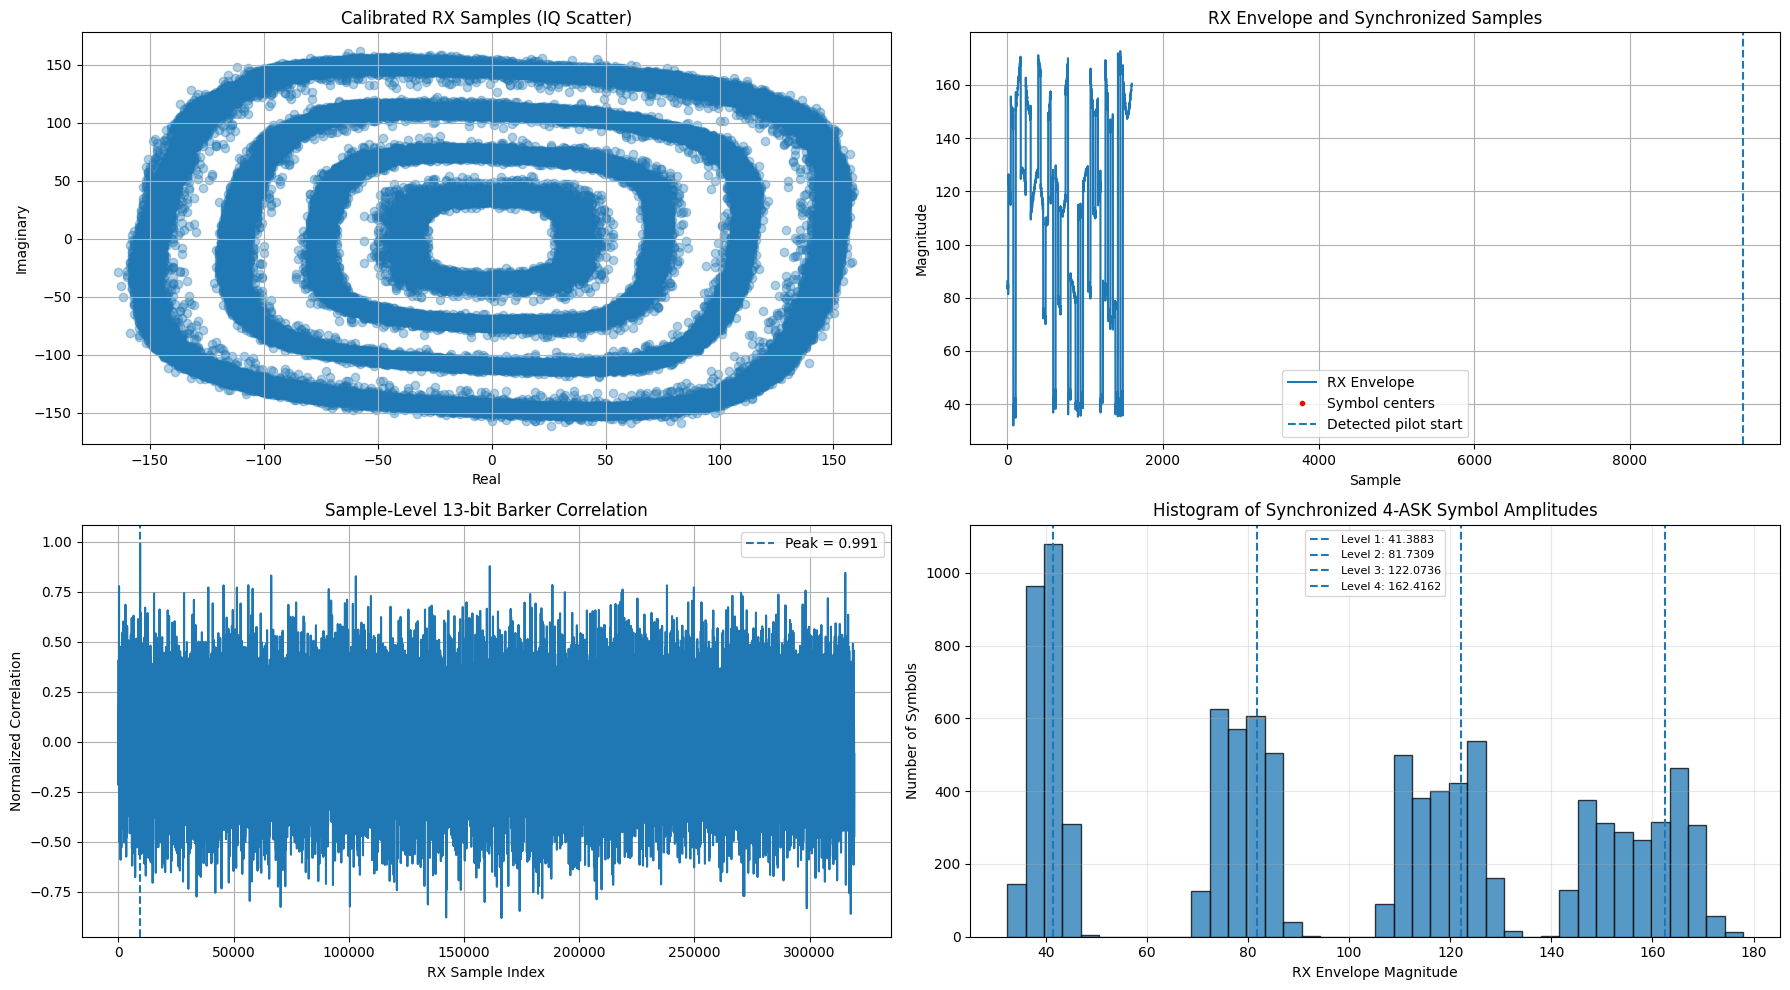

In [7]:
plt.figure(figsize=(18, 10))

# ------------------------------------------------------------
# Panel 1: Calibrated RX IQ scatter
# ------------------------------------------------------------
plt.subplot(2, 2, 1)
plt.scatter(rx_calibrated.real, rx_calibrated.imag, alpha=0.35)
plt.title('Calibrated RX Samples (IQ Scatter)')
plt.xlabel('Real')
plt.ylabel('Imaginary')
plt.grid(True)

# ------------------------------------------------------------
# Panel 2: RX envelope with synchronized symbol centers
# ------------------------------------------------------------
plt.subplot(2, 2, 2)
plot_len = min(50*sps, len(rx_envelope))
plt.plot(rx_envelope[:plot_len], label='RX Envelope')

marker_positions = (
    pilot_start_sample + np.arange(50) * sps
) % len(rx_envelope)

valid = marker_positions < plot_len
plt.plot(
    marker_positions[valid],
    rx_envelope[marker_positions[valid].astype(int)],
    'ro',
    ms=3,
    label='Symbol centers'
)

plt.axvline(
    pilot_start_sample,
    linestyle='--',
    label='Detected pilot start'
)

plt.title('RX Envelope and Synchronized Samples')
plt.xlabel('Sample')
plt.ylabel('Magnitude')
plt.grid(True)
plt.legend()

# ------------------------------------------------------------
# Panel 3: Sample-level Barker correlation
# ------------------------------------------------------------
plt.subplot(2, 2, 3)
plt.plot(sync['correlation_curve'])
plt.axvline(
    pilot_start_sample,
    linestyle='--',
    label=f'Peak = {sync_correlation:.3f}'
)
plt.title('Sample-Level 13-bit Barker Correlation')
plt.xlabel('RX Sample Index')
plt.ylabel('Normalized Correlation')
plt.grid(True)
plt.legend()

# ------------------------------------------------------------
# Panel 4: Histogram of synchronized symbol amplitudes
# ------------------------------------------------------------
# Reconstruct one complete frame starting at the detected Barker peak.
total_frame_samples = len(tx_waveform)

if len(rx_envelope) < total_frame_samples:
    repeats = int(np.ceil(
        (pilot_start_sample + total_frame_samples) / len(rx_envelope)
    ))
    rx_stream_task6 = np.tile(rx_envelope, repeats)
else:
    rx_stream_task6 = rx_envelope

frame_wave_task6 = rx_stream_task6[
    int(pilot_start_sample):
    int(pilot_start_sample) + total_frame_samples
]

# Sample at the center of every symbol in the frame.
symbol_centers_task6 = (
    sps // 2
    + np.arange(PILOT_LEN + len(tx_amplitudes)) * sps
)

symbol_samples_task6 = frame_wave_task6[symbol_centers_task6]

plt.subplot(2, 2, 4)
plt.hist(
    symbol_samples_task6,
    bins=40,
    alpha=0.75,
    edgecolor='black'
)

# Show the expected RX amplitude locations after pilot-based
# calibration, so the four 4-ASK levels can be identified.
pilot_rx_task6 = symbol_samples_task6[:PILOT_LEN]

A_task6 = np.column_stack([
    pilot_amplitudes.astype(float),
    np.ones(PILOT_LEN)
])

rx_scale_task6, rx_offset_task6 = np.linalg.lstsq(
    A_task6,
    pilot_rx_task6.astype(float),
    rcond=None
)[0]

expected_levels_task6 = (
    rx_scale_task6 * ASK4_LEVELS + rx_offset_task6
)

for i, level in enumerate(expected_levels_task6):
    plt.axvline(
        level,
        linestyle='--',
        linewidth=1.5,
        label=f'Level {i+1}: {level:.4f}'
    )

plt.title('Histogram of Synchronized 4-ASK Symbol Amplitudes')
plt.xlabel('RX Envelope Magnitude')
plt.ylabel('Number of Symbols')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8)

plt.tight_layout()
plt.show()


## Task 7: Amplitude Decision and Payload Bit Recovery

Use the Barker peak as the frame start, skip the 13 pilot symbols, and decode only the following
4-ASK payload symbols. The pilot is never counted as payload data or as BER errors.


In [8]:
# ============================================================
# TASK 7: FRAME EXTRACTION + 4-ASK DEMODULATION
# ============================================================

payload_bits_len = len(tx_bits)
payload_symbols_len = len(tx_amplitudes)
pilot_samples_len = PILOT_LEN * sps
total_frame_samples = len(tx_waveform)

print(f"TX payload bits      : {payload_bits_len}")
print(f"TX payload symbols   : {payload_symbols_len}")
print(f"Pilot samples        : {pilot_samples_len}")
print(f"TX frame samples     : {total_frame_samples}")
print(f"RX capture samples   : {len(rx_envelope)}")

# Pluto TX is cyclic. Repeat the captured RX stream when necessary so
# a complete frame can be extracted from the detected Barker start.
if len(rx_envelope) < total_frame_samples:
    repeats = int(np.ceil(
        (pilot_start_sample + total_frame_samples) / len(rx_envelope)
    ))
    rx_stream = np.tile(rx_envelope, repeats)
else:
    rx_stream = rx_envelope

frame_start = int(pilot_start_sample)
frame_wave_envelope = rx_stream[
    frame_start:frame_start + total_frame_samples
]

if len(frame_wave_envelope) < total_frame_samples:
    raise RuntimeError(
        f"Insufficient RX data: got {len(frame_wave_envelope)} samples, "
        f"need {total_frame_samples}."
    )

# Sample at the center of each symbol.
center_offset = sps // 2
symbol_centers = center_offset + np.arange(
    PILOT_LEN + payload_symbols_len
) * sps

frame_samples = frame_wave_envelope[symbol_centers]

# ------------------------------------------------------------
# Pilot-based amplitude calibration
# ------------------------------------------------------------
pilot_rx = frame_samples[:PILOT_LEN]

A = np.column_stack([
    pilot_amplitudes.astype(float),
    np.ones(PILOT_LEN)
])

rx_scale, rx_offset = np.linalg.lstsq(
    A, pilot_rx.astype(float), rcond=None
)[0]

if abs(rx_scale) < 1e-12:
    raise RuntimeError(f"Invalid RX amplitude scale: {rx_scale}")

# Remove the 13-symbol Barker pilot before decoding.
payload_rx_samples = (
    frame_samples[PILOT_LEN:] - rx_offset
) / rx_scale

print(f"Recovered payload symbols : {len(payload_rx_samples)}")
print(f"RX amplitude scale        : {rx_scale:.6g}")
print(f"RX amplitude offset       : {rx_offset:.6g}")

# ------------------------------------------------------------
# Nearest-level 4-ASK detection
# ------------------------------------------------------------
distances = np.abs(
    payload_rx_samples[:, None] -
    ASK4_LEVELS[None, :]
)

rx_level_indices = np.argmin(distances, axis=1)

# Gray decoding:
# level 0 -> 00
# level 1 -> 01
# level 2 -> 11
# level 3 -> 10
rx_bits = ASK4_GRAY[rx_level_indices].reshape(-1).astype(np.uint8)

rx_bits = rx_bits[:len(tx_bits)]

print(f"Recovered payload bits : {len(rx_bits)}")


TX payload bits      : 20000
TX payload symbols   : 10000
Pilot samples        : 416
TX frame samples     : 320416
RX capture samples   : 319416
Recovered payload symbols : 10000
RX amplitude scale        : 0.0393971
RX amplitude offset       : 1.0457
Recovered payload bits : 20000


## Task 8: Measure the Bit Error Rate

The Barker pilot has synchronized the frame, so the recovered payload bits correspond directly to
`tx_bits`. The 13 pilot bits are excluded from the BER calculation.


In [9]:
# ============================================================
# TASK 8: PAYLOAD-ONLY BER
# ============================================================

compare_length = min(len(rx_bits), len(tx_bits))

if compare_length == 0:
    n_bit_errors = 0
    ber = 1.0
else:
    n_bit_errors = int(
        np.sum(rx_bits[:compare_length] != tx_bits[:compare_length])
    )
    ber = n_bit_errors / compare_length

print(
    f"Bit errors: {n_bit_errors} / {compare_length} "
    f"(BER = {ber:.6g})"
)


Bit errors: 357 / 20000 (BER = 0.01785)


## Task 9: Bit Error Rate versus Transmit Gain

Repeat the transmit-capture-detect-score procedure from Tasks 3 through 8 at several different
transmit hardware gain settings, holding the receive gain fixed throughout, to see how the bit
error rate responds as the received signal strength changes relative to a fixed noise floor.

Wrap the full procedure in a function, so you can call it once per gain setting without
retyping it. Sweep a handful of gain values spanning from clearly error-free down to clearly
unusable. Plot the resulting bit error rate on a logarithmic vertical axis against the gain
values on a linear horizontal axis.

## Important BER and Frame-Synchronization Fixes in V3

1. **Sample-level Barker correlation:** the complete 13-symbol Barker waveform (416 samples at `sps=32`) is correlated at every RX sample position.
2. **No artificial `sps//2` timing offset:** the detected pilot start is the actual sample index. Symbol centers are added only after frame alignment.
3. **Proper cyclic-frame reconstruction:** RX captures exactly one TX-frame period, and synchronized frame samples wrap modulo the known TX waveform length.
4. **Consistent Gray mapping:** TX uses `gray_to_level = [0,1,3,2]`, matching the RX table.
5. **Pilot excluded from BER:** the 13-symbol Barker pilot is removed before payload bit comparison.
6. **Pilot-based amplitude calibration:** the known pilot levels estimate RX amplitude scale/offset.
7. **Gain sweep uses the actual requested TX gain** and the same sample-level synchronization path.


TX gain=-50.0 dB | pilot_start_sample=  10505 | Barker corr=0.984 | BER=0
TX gain=-45.0 dB | pilot_start_sample=  10048 | Barker corr=0.991 | BER=0
TX gain=-40.0 dB | pilot_start_sample=  10163 | Barker corr=0.981 | BER=0
TX gain=-35.0 dB | pilot_start_sample=  10157 | Barker corr=0.991 | BER=5e-05
TX gain=-30.0 dB | pilot_start_sample=  10123 | Barker corr=0.988 | BER=0
TX gain=-25.0 dB | pilot_start_sample=  10221 | Barker corr=0.988 | BER=0
TX gain=-20.0 dB | pilot_start_sample=   9852 | Barker corr=0.993 | BER=0
TX gain=-15.0 dB | pilot_start_sample=  10335 | Barker corr=0.995 | BER=0
TX gain=-10.0 dB | pilot_start_sample=  10138 | Barker corr=0.992 | BER=0
TX gain= -5.0 dB | pilot_start_sample=  10281 | Barker corr=0.994 | BER=0


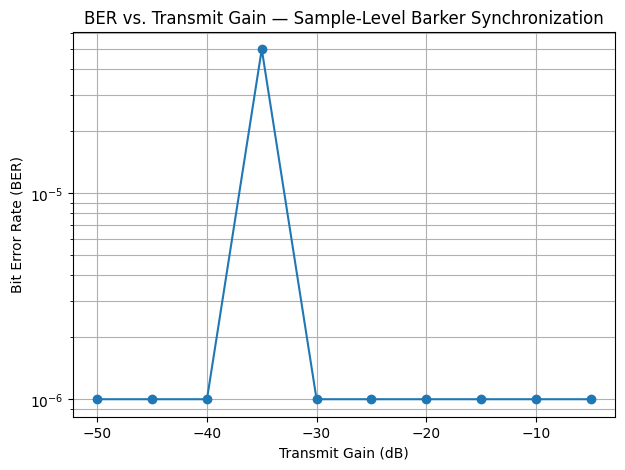

In [10]:
def find_barker_frame_start_fast(rx_envelope, sps, barker_bits):
    """Sample-level Barker synchronizer used by the BER-vs-gain sweep."""
    b = np.asarray(barker_bits, dtype=float)
    pilot_levels = np.where(b > 0, ASK4_LEVELS[3], ASK4_LEVELS[0])
    template = np.repeat(pilot_levels, sps).astype(float)
    corr = normalized_correlation(rx_envelope, template)
    pilot_start = int(np.argmax(corr))
    return float(corr[pilot_start]), pilot_start, corr


def measure_ber_at_gain(tx_gain_db):
    """Transmit a Barker-synchronized 4-ASK frame and return payload BER."""
    tx_sdr.tx_hardwaregain_chan0 = -15

    current_tx_bits = np.random.randint(0, 2, n_bits)
    current_tx_symbols = (current_tx_bits[::2] << 1) | current_tx_bits[1::2]
    current_tx_level_indices = gray_to_level[current_tx_symbols]
    current_tx_amplitudes = ASK4_LEVELS[current_tx_level_indices]
    current_frame_amplitudes = np.concatenate([pilot_amplitudes, current_tx_amplitudes])
    current_tx_waveform = np.repeat(current_frame_amplitudes, sps).astype(np.complex64)

    # Capture exactly one cyclic frame period.
    rx_sdr.rx_buffer_size = len(current_tx_waveform)
    tx_sdr.tx_cyclic_buffer = True
    tx_sdr.tx(current_tx_waveform)
    time.sleep(0.5)
    current_rx_raw = rx_sdr.rx()
    tx_sdr.tx_destroy_buffer()
    try:
        rx_sdr.rx_destroy_buffer()
    except Exception:
        pass

    current_rx_cal = np.asarray(current_rx_raw).flatten() - dc_offset
    current_env = np.abs(current_rx_cal)
    corr, pilot_start_sample, _ = find_barker_frame_start_fast(current_env, sps, BARKER_13)

    frame_idx = (pilot_start_sample + np.arange(len(current_tx_waveform))) % len(current_tx_waveform)
    frame_env = current_env[frame_idx]
    centers = sps // 2 + np.arange(PILOT_LEN + len(current_tx_amplitudes)) * sps
    frame_samples = frame_env[centers]

    A = np.column_stack([pilot_amplitudes, np.ones(PILOT_LEN)])
    scale, offset = np.linalg.lstsq(A, frame_samples[:PILOT_LEN], rcond=None)[0]
    if scale <= 0:
        return 1.0

    payload_samples = (frame_samples[PILOT_LEN:] - offset) / scale
    rx_levels = np.argmin(
        np.abs(payload_samples[:, None] - ASK4_LEVELS[None, :]), axis=1
    )
    recovered_bits = ASK4_GRAY[rx_levels].flatten()[:n_bits]
    ber = float(np.mean(recovered_bits != current_tx_bits[:len(recovered_bits)]))

    print(f"TX gain={tx_gain_db:5.1f} dB | pilot_start_sample={pilot_start_sample:7d} | Barker corr={corr:.3f} | BER={ber:.6g}")
    return ber


tx_gain_sweep_db = np.arange(-50, 0, 5)
ber_results = [measure_ber_at_gain(g) for g in tx_gain_sweep_db]

plt.figure(figsize=(7, 5))
plt.semilogy(tx_gain_sweep_db, np.maximum(ber_results, 1e-6), 'o-')
plt.xlabel('Transmit Gain (dB)')
plt.ylabel('Bit Error Rate (BER)')
plt.title('BER vs. Transmit Gain — Sample-Level Barker Synchronization')
plt.grid(True, which='both', ls='-')
plt.show()


## Background

**DC offset and LO leakage.** A small amount of a receiver's own local-oscillator signal
routinely couples into its receive path, and analog mixers and amplifiers carry their own
small imbalances. Together these show up as a constant complex offset added to every sample,
independent of whatever signal is actually arriving over the air. It doesn't average away on
its own, and unless it's measured and removed, it biases the center of every constellation and
every amplitude measurement you take afterward.

**Why magnitude ignores phase rotation.** A complex sample can be written as an amplitude
multiplied by a unit-magnitude phase factor. When two independently clocked oscillators drift
relative to one another, that phase factor rotates steadily over time, tracing out a spiral in
the IQ plane. Taking the magnitude of the sample discards the phase factor entirely, leaving
only the amplitude behind. This is why a coherent receiver (one that reads off phase, or a
signal's exact IQ position) must actively track and undo that rotation before it can make
correct decisions, while a receiver based purely on magnitude is unaffected by it from the
start. The cost is that magnitude alone cannot distinguish anything encoded in phase — it
only works because 4-ASK put no information there in the first place.

**Nearest-level decision.** In additive noise that is symmetric around zero, the most likely
transmitted amplitude, given a noisy received value, is simply whichever ideal level that
value sits closest to. This is the same reasoning you've applied to constellation points in
two dimensions, just restricted to points on a single positive axis. It's the optimal rule
precisely when the noise distribution is symmetric and the levels are used equally often —
both true here.

**Rectangular pulses and single-sample detection.** Holding each amplitude constant for the
full symbol duration, rather than shaping it some other way, means a single sample from the
middle of that duration is already a reasonable estimate of the transmitted amplitude — the
signal isn't changing there. This is a much simpler stand-in for the kind of matched filtering
you'd use with a non-rectangular pulse, where you'd want to combine information from many
samples rather than rely on just one.

## Questions

1. Why does subtracting the DC offset measured in Task 1 matter for the histogram you produced
   in Task 6? Sketch, in words, what that histogram would look like if you skipped this step.

2. The raw IQ scatter in Task 6 traces out a rotating pattern, but the amplitude histogram
   built from the same samples still shows four clean levels. In your own words, explain why
   the rotation doesn't interfere with the decision made in Task 7.

3. Suppose you doubled `sps` while keeping the total number of transmitted bits the same.
   Would you expect the bit error rate at a fixed transmit gain to improve, get worse, or stay
   about the same? Explain your reasoning.

4. In Task 9, would lowering the fixed receive gain produce the same effect on the BER curve as
   raising the transmit gain? Why or why not?

### Lab Questions & Answers

**1. Why does subtracting the DC offset measured in Task 1 matter for the histogram you produced in Task 6? Sketch, in words, what that histogram would look like if you skipped this step.**

* **The "Why":** Envelope detection calculates the magnitude of the signal using the formula $\sqrt{I^2 + Q^2}$. A DC offset acts as a constant vector added to your incoming signal. Because the incoming signal is continuously rotating in phase (due to oscillator mismatch), this constant DC vector can sometimes add constructively to the signal and sometimes destructively. 
* **The Result:** Instead of calculating the true amplitude of the symbol, the receiver calculates a magnitude that fluctuates wildly as the signal spins.
* **The Histogram Without Calibration:** If you skipped this step, the histogram would not show four clean, distinct peaks. Instead, acording to me the rotation combined with the offset would cause the amplitudes to smear across the x-axis. The histogram would look like one wide, messy mound or heavily overlapping Gaussian , making it impossible to accurately distinguish the four 4-ASK amplitude levels.

**2. The raw IQ scatter in Task 6 traces out a rotating pattern, but the amplitude histogram built from the same samples still shows four clean levels. In your own words, explain why the rotation doesn't interfere with the decision made in Task 7.**

* **Phase vs. Magnitude:** The rotating pattern in the IQ scatter plot is caused by carrier frequency and phase mismatches between the independent transmitter and receiver oscillators. This rotation means the *phase angle* of the signal is constantly changing.
* **Why its not causing problem:** The decision in Task 7 is based entirely on envelope detection, which is theritically based on MLE(maximum likelihood estimation) ,which only looks at the absolute distance of the sample from the origin (its magnitude), completely ignoring the phase angle. Because the points are just spinning in a circle around the origin, their distance from the center stays perfectly constant. Therefore, the rotation has zero impact on the amplitude levels, allowing the four levels to remain clean and distinct.

**3. Suppose you doubled `sps` while keeping the total number of transmitted bits the same. Would you expect the bit error rate at a fixed transmit gain to improve, get worse, or stay about the same? Explain your reasoning.**

* **Expectation:** The Bit Error Rate (BER) would certainly **improve**.
* **Reasoning:** The `sps` variable stands for "samples per symbol." If you double the `sps` while keeping the total bits and transmit gain the same, you are effectively transmitting each symbol for twice as long in time. This puts twice as much signal energy into the air for every single symbol. This results in a higher Signal-to-Noise Ratio (SNR) per symbol, which directly leads to fewer errors and an improved BER but effectively we are only sending half the information in same amount of time so this is a tradeoff .

**4. In Task 9, would lowering the fixed receive gain produce the same effect on the BER curve as raising the transmit gain? Why or why not?**

* **Expectation:** No, it would **not** produce the same effect.
* **Reasoning:** Raising the **transmit gain** actually increases the physical power of the signal being sent over the air. This makes the signal louder relative to the environmental noise in the channel, directly improving your Signal-to-Noise Ratio (SNR) and lowering your BER. 
* On the other hand, the **receive gain** is just an internal amplifier at the receiver. It amplifies *everything* the antenna picks up—both the desired signal and the channel noise equally. Lowering it just makes both the signal and the noise quieter by the exact same proportion. Because the ratio of signal to noise (SNR) remains unchanged, adjusting the receive gain will not improve your BER .

### Barker synchronization reference

Barker-13 used in this notebook:
`[+1,+1,+1,+1,+1,-1,-1,+1,+1,-1,+1,-1,+1]`

V3 converts this sequence into the actual high/low 4-ASK envelope waveform and correlates that 416-sample
template at **every RX sample position**. The detected sample is the beginning of the first pilot symbol.
The receiver then reconstructs one complete cyclic frame modulo the known TX frame length, samples at symbol
centers, discards the 13 pilot symbols, and calculates BER only on the payload bits.
